# SonicCaption — Notebook 04: Real-Time Spectral Enhancement, Pitch Diarization & Acoustic-Aware Agent
**MAI522-5 Speech Processing & Recognition · Member 1 Product Extension (Units 1–3 DSP + Product Intelligence)**

This notebook proves and validates the production DSP upgrades that power SonicCaption's live product layer:
1. **Boll's Spectral Subtraction Denoising (OLA):** Removes stationary background hum/fan noise while measuring Segmental SNR gain.
2. **Fundamental Pitch ($F_0$) Contour Estimation:** Autocorrelation periodicity tracking coupled with Energy/ZCR voicing decisions.
3. **MFCC + $F_0$ + K-Means VQ Speaker Diarization:** Automatically separates speaker turns (`Speaker 1`, `Speaker 2`).
4. **Acoustic-Aware Reminder & Agent Pipeline:** Combines speech transcripts, environmental cues, and SQLite session logging.


In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..') / 'backend' / 'src'))
from soniccaption.audio.io import generate_synthetic_signal
from soniccaption.algorithms.enhancement import (
    spectral_subtraction_denoise,
    estimate_pitch_contour,
    diarize_speakers,
)
from soniccaption.algorithms.spectral import compute_stft
from soniccaption.services.agent_service import extract_session_insights, run_voice_agent_turn
print('Loaded Member 1 enhancement & agent modules cleanly.')


Loaded Member 1 enhancement & agent modules cleanly.


## 1. Spectral Subtraction Denoising & SNR Benchmark (Unit 1 & 2 DSP)
We synthesize a voiced benchmark with a silent noise-only prefix, inject white acoustic noise, and apply Boll's spectral subtraction (`alpha=1.6`, floor `0.08`).

Noise floor RMS: 0.02765 | SNR Before: 18.49 dB -> After: 34.25 dB (Gain: +15.76 dB)


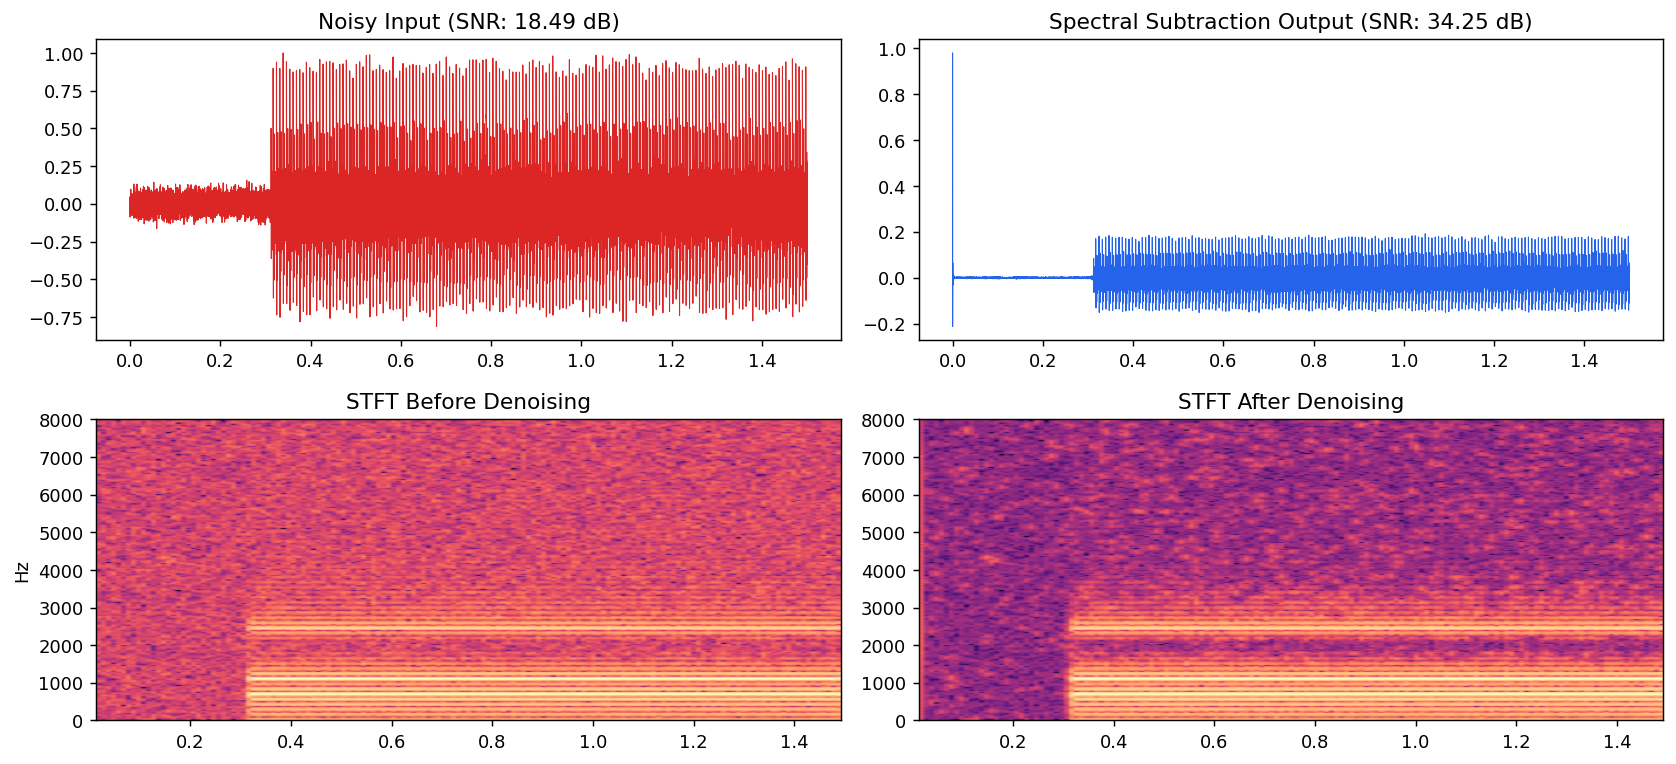

In [2]:
sr = 16000
clean = generate_synthetic_signal('vowel_ah', duration=1.5, sr=sr, f0=135.0).samples
clean[:5000] = 0.0
rng = np.random.default_rng(42)
noisy = (clean + 0.045 * rng.standard_normal(len(clean))).astype(np.float32)
den_res = spectral_subtraction_denoise(noisy, sr=sr)
denoised = den_res['denoised']
print(f"Noise floor RMS: {den_res['noise_floor_rms']} | SNR Before: {den_res['snr_before_db']} dB -> After: {den_res['snr_after_db']} dB (Gain: +{den_res['snr_gain_db']} dB)")

f_n, t_n, spec_noisy = compute_stft(noisy, sr)
f_d, t_d, spec_den = compute_stft(denoised, sr)
fig, axes = plt.subplots(2, 2, figsize=(13, 6))
axes[0, 0].plot(np.arange(len(noisy)) / sr, noisy, color='#dc2626', lw=0.6)
axes[0, 0].set_title(f'Noisy Input (SNR: {den_res["snr_before_db"]} dB)')
axes[0, 1].plot(np.arange(len(denoised)) / sr, denoised, color='#2563eb', lw=0.6)
axes[0, 1].set_title(f'Spectral Subtraction Output (SNR: {den_res["snr_after_db"]} dB)')
axes[1, 0].imshow(spec_noisy, aspect='auto', origin='lower', cmap='magma', extent=[t_n[0], t_n[-1], 0, 8000])
axes[1, 0].set_title('STFT Before Denoising'); axes[1, 0].set_ylabel('Hz')
axes[1, 1].imshow(spec_den, aspect='auto', origin='lower', cmap='magma', extent=[t_d[0], t_d[-1], 0, 8000])
axes[1, 1].set_title('STFT After Denoising')
plt.tight_layout(); plt.show()


## 2. Pitch ($F_0$) Tracking & VQ Speaker Turn Diarization
We concatenate alternating turns from two speakers (`Speaker 1` at `120 Hz` vowel /a/, `Speaker 2` at `230 Hz` vowel /i/) and run `diarize_speakers`.

[0.00-0.80s] Speaker 1: Hi team, remind me to push the release today.
[1.05-1.85s] Speaker 2: Sure, wait I hear a knock at the door.
[2.10-2.90s] Speaker 1: Let me check that now.


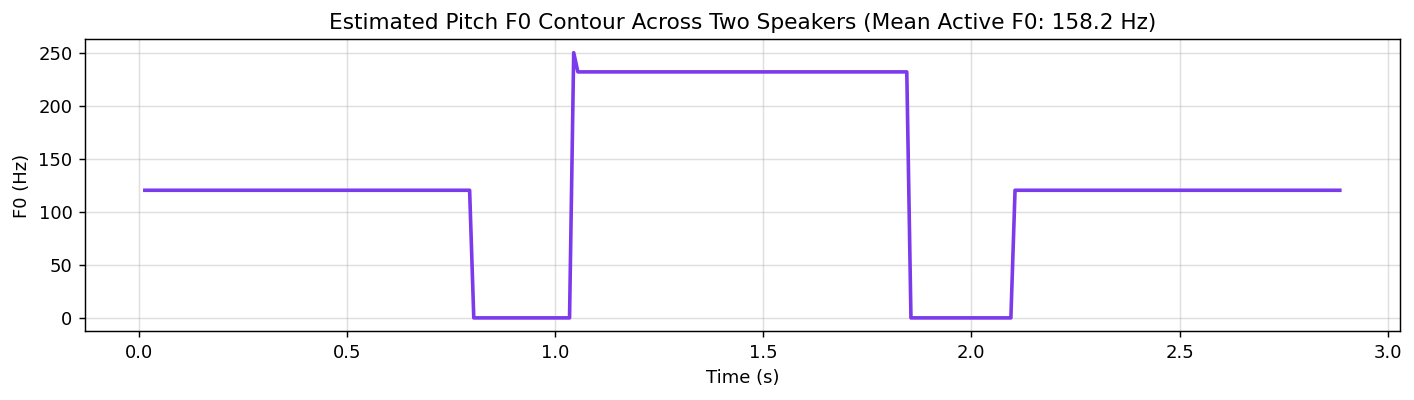

In [3]:
spk1 = generate_synthetic_signal('vowel_ah', duration=0.8, sr=sr, f0=120.0).samples
spk2 = generate_synthetic_signal('vowel_ee', duration=0.8, sr=sr, f0=230.0).samples
gap = np.zeros(int(0.25 * sr), dtype=np.float32)
dialogue = np.concatenate([spk1, gap, spk2, gap, spk1])
pitch = estimate_pitch_contour(dialogue, sr=sr)
segments = [
    {'start': 0.0, 'end': 0.8, 'text': 'Hi team, remind me to push the release today.'},
    {'start': 1.05, 'end': 1.85, 'text': 'Sure, wait I hear a knock at the door.'},
    {'start': 2.1, 'end': 2.9, 'text': 'Let me check that now.'},
]
diarized = diarize_speakers(dialogue, segments, sr=sr, max_speakers=2)
for seg in diarized:
    print(f"[{seg['start']:.2f}-{seg['end']:.2f}s] {seg['speaker']}: {seg['text']}")

plt.figure(figsize=(11, 3.2))
plt.plot(pitch['times'], pitch['f0_hz'], color='#7c3aed', lw=2)
plt.title(f'Estimated Pitch F0 Contour Across Two Speakers (Mean Active F0: {pitch["mean_f0_hz"]} Hz)')
plt.xlabel('Time (s)'); plt.ylabel('F0 (Hz)'); plt.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()


## 3. Acoustic-Aware AI Copilot & Reminder Extraction Validation
Demonstrates combining speech transcripts + environmental tags (`door_wood_knock`) + vocal pitch into structured reminders and spoken responses.

In [4]:
mock_events = [{'start': 1.2, 'end': 2.0, 'label': 'Door knock', 'confidence': 0.87}]
insights = extract_session_insights(diarized, mock_events, pitch_stats=pitch)
print('Session Summary:', insights['summary'])
print('Auto-Extracted Reminders:', insights['reminders'])

turn = run_voice_agent_turn('Remind me to check the model weights tonight.', mock_events, pitch_stats=pitch)
print('Agent Voice Reply:', turn['reply'])


Session Summary: Detected speech (2 speakers): "Hi team, remind me to push the release today. Sure, wait I hear a knock at the door. Let me check that now." Ambient context: Door knock (87%). Mean vocal F0: 158.2 Hz.
Auto-Extracted Reminders: [{'title': 'Push the release today', 'due_time': 'Today', 'priority': 'medium', 'trigger_source': 'speech_action'}, {'title': 'Door knock heard — check entrance', 'due_time': 'At 1.2s', 'priority': 'medium', 'trigger_source': 'acoustic_alert'}]
Agent Voice Reply: Heads up—I also heard Door knock in your background audio. Got it, I saved that reminder for you: Check the model weights tonight.
